## COMP5712M: Programming for Data Science 

## Group project: Data Analysis Project


# _Project Title_ - please name your project


_Give names and emails of group members here:_

* Weijie Xu, jbkk0017@leeds.ac.uk

# Project Plan

## The Data (10 marks)

_Here you should describe the data including details of:
where it comes from, what data it contains, is it accurate. (Potentially you could create data from a simulation but you should still explain why and how you intend to generate this data.)_

_It can be just one dataset or several that can be combined
logically. To ensure sufficient depth for analysis, the final dataset must contain a mininum of 1000 rows and 7 features._

_There are 10 marks for this, so a fairly detailed description
of the data is expected. You should include details including the size, the features, range of values, and so on._



## Project Aim and Objectives (5 marks)

_Here you should describe the general aim of your project in
around 200-300 words._

_This can can be anything from classifying items according to
their characteristic features (which mushrooms are poisonous?) 
to simulating an evolving process (will the rabbits eat all
the carrots or get eaten by the foxes?)_

_Here some ideas of general types of processing functionality
that you could implement:_

* _Classification: separate data items into classes according
  to their charactersitics (can be either a definite or a
  statistical kind of classification)_
* _Corellation: find correspondences between different attributes within
  a dataset_
* _Search: find solutions matching some criteria_
* _Visualisation: find informative ways to
  display the structure of a large and/or complex dataset useful for decision making_
* _Query Answering: create a system that enables one to retrieve information by evaluating some form of query representation_
* _Simulation: model the evolution of a complex process_

### Specific Objective(s)

_You should chose and list __up to 4__ specific objectives suited to the data you will be working with and the type of project you wish to carry out according to the project aim. 
There should be <b>at least one
per person doing the project</b>. There is no need
for  the objectives them to be completely different. 
They could be different
stages of the processing requirements, or different processing
functions that the system  provides. Or just
different aspects of data analysis that will be conducted.
Typically, it is expected that there would be one objective
per person. Replace the following examples with your own objectives:_

* __Objective 1:__ _create a Python datastructure that will ensure world peace_
* __Objective 2:__ _stop global warming using a pandas dataframe_
* __Objective 3:__ _end poverty using matplotlib_
* __Objective 4:__ _Future Adoption and Resistance_

## System Design (5 marks)

_Describe your code in terms of the
following two sections._

### Architecture

_Typically this would be  a pipeline in which __data__ goes through several
stages of transformation and analysis, but other architectures are possible.
This does not need to be particularly complicated. A simple diagram with
100-150 words of explanation would
be a good way to present your architecture._
  
### Processing Modules and Algorithms

_Briefly list and describe the most significant computational components of your system and the algorithms you will use to implement them. 
This could include things like:_

* _cleaning the data by removing outliers_
* _combining different datasets_
* _converting samples to a special representation (such as feature vectors)_
* _constructing a special data-structure (such as a decision tree)_
* _running some kind of analysis_

_Your list can be presented in similar form to the one just given, 
but should include a brief
but more specific description of the components and/or algorithms.
Probably three or four components is sufficient for most projects, but
you may want to have more._



# Program Code (15 marks)


Please note the following about your code:
* <b><i>You may import any packages/modules you wish to use for your project.</i></b> However, for special packages/modules, it would be nice to put comments or a sentence on where these modules are used in the project.


* <b><i>You should submit your notebook in a state where all cells have been
    executed and are displaying the output that you wish to present for grading.</i></b>
    (We will not normally run your code, unless for some reason we wish to check
    that the code functionality matches the given description.)
    
    
* It is strongly suggested you use __function definitions to organise your code__. As well as being generally good programming practice, it will be helpful for easy and flexibily presentation of results visualisations later in the document. In the visualisation sections you will be able to produce images in a concise and flexible way by calling functions defined in the program code secion.

## Shared raw data import

<!-- 读取原始 CSV 并建立 SQLite 数据库；schema 是字段说明，不是受访者数据。 -->

In [22]:
from contextlib import closing
from pathlib import Path
import sqlite3
import pandas as pd

# Notebook 和两个 CSV 文件位于同一目录。
responses_file = 'survey_results_public.csv'
schema_file = 'survey_results_schema.csv'
data_dir = Path.cwd()

# 保留原始文本值，缺失值的处理留给后续分析。
responses_df = pd.read_csv(
    data_dir / responses_file,
    dtype=str,
    keep_default_na=False,
)
columns_meta_df = pd.read_csv(
    data_dir / schema_file,
    dtype=str,
    keep_default_na=False,
)

db_path = (data_dir / 'survey.db').resolve()

# 建立数据库并导入两张表；重复运行时替换旧表。
with sqlite3.connect(db_path) as conn:
    responses_df.to_sql('responses', conn, if_exists='replace', index=False)
    columns_meta_df.to_sql('columns_meta', conn, if_exists='replace', index=False)

## Member A: Objective 1 - Current AI Adoption: Where Do Respondents Currently Use AI?

#### Step 1: Query the database

First, we select the columns needed: ResponseId, AISelect, AIWorkCurrentlyUse, AIWorkExpectMore, AIWorkExpectLess, AIWorkDoNotPlanToUse, and AIWorkNotInWorkflow. We include all 30,903 respondents, not only those CodeMain reponses. Then, we retrieve the exact meaning of these columns from the columns_meta table and save the information in work_schema.

In [23]:
with closing(sqlite3.connect(db_path.as_uri() + '?mode=ro', uri=True)) as conn:
    work_df = pd.read_sql_query('''
        SELECT ResponseId, AISelect, AIWorkCurrentlyUse, AIWorkExpectMore,
               AIWorkExpectLess, AIWorkDoNotPlanToUse, AIWorkNotInWorkflow
        FROM responses
    ''', conn)
    work_schema = pd.read_sql_query('''
        SELECT "column", question, sub, source_columns, transformation, nonmissing
        FROM columns_meta
        WHERE "column" IN ('AISelect', 'AIWorkCurrentlyUse', 'AIWorkExpectMore',
                           'AIWorkExpectLess', 'AIWorkDoNotPlanToUse', 'AIWorkNotInWorkflow')
    ''', conn)

print(f'read {len(work_df):,} respondents')
display(work_schema[['column', 'sub', 'question']].rename(
    columns={'sub': 'answer_meaning'}
))

read 30,903 respondents


,column,answer_meaning,question
0,AISelect,NA,Do you currently use AI tools or AI agents in your role at work?
1,AIWorkCurrentlyUse,Currently use AI or AI agents for this,Which parts of your workflow are you currently integrating into AI or using AI agents to accomplish? Will they be more or less integrated over the...
2,AIWorkExpectMore,Expect to use AI More or AI agents more for this,Which parts of your workflow are you currently integrating into AI or using AI agents to accomplish? Will they be more or less integrated over the...
3,AIWorkExpectLess,Expect to use AI or AI agents less for this,Which parts of your workflow are you currently integrating into AI or using AI agents to accomplish? Will they be more or less integrated over the...
4,AIWorkDoNotPlanToUse,Do not use AI or AI agents for this and do not plan to,Which parts of your workflow are you currently integrating into AI or using AI agents to accomplish? Will they be more or less integrated over the...
5,AIWorkNotInWorkflow,This is not part of my workflow,Which parts of your workflow are you currently integrating into AI or using AI agents to accomplish? Will they be more or less integrated over the...


The query gives 30,903 respondents. We can also see the question related to each column and what each column means when it appears as an answer.

#### Step 2: Data cleaning - Data preparation

This step prepares the data for analysis and checks its completeness. We copy the five AIWork fields and treat blank strings and "NA" values as missing. We then count the non-missing responses in each field and compare these counts with the original values recorded in the schema. The counts match for all five fields. No respondents are removed in this step.

In [24]:
work_columns = [
    'AIWorkCurrentlyUse',
    'AIWorkExpectMore',
    'AIWorkExpectLess',
    'AIWorkDoNotPlanToUse',
    'AIWorkNotInWorkflow'
]

work_clean = work_df.copy()
work_clean[work_columns] = work_clean[work_columns].replace({
    '': pd.NA,
    'NA': pd.NA
})

observed = work_clean[work_columns].notna().sum()

expected = (
    work_schema
    .set_index('column')['nonmissing']
    .astype(int)
    .reindex(work_columns)
)

comparison = pd.DataFrame({
    'schema_nonmissing': expected,
    'observed_nonmissing': observed
})
comparison['matches'] = (
    comparison['schema_nonmissing']
    == comparison['observed_nonmissing']
)

print('Comparison with schema non-missing counts:')
display(comparison)



Comparison with schema non-missing counts:


,schema_nonmissing,observed_nonmissing,matches
AIWorkCurrentlyUse,11210,11210,True
AIWorkExpectMore,10189,10189,True
AIWorkExpectLess,5296,5296,True
AIWorkDoNotPlanToUse,8338,8338,True
AIWorkNotInWorkflow,7783,7783,True


There are 12,547 respondents with an answer in at least one AIWork field. The counts for different fields can overlap because one respondent can answer more than one field.

#### Step 3: Data cleaning - Reshaping data

Each AIWork field can contain several tasks separated by ';'. We separate these tasks so that each row shows one person, one AI-use status, and one task. We then remove repeated rows. This means that the same person is counted only once for the same task and status.

In [25]:
aiwork_long_df = work_clean.melt(
    id_vars='ResponseId',
    value_vars=work_columns,
    var_name='status',
    value_name='task',
)

aiwork_long_df = aiwork_long_df.dropna(subset=['task'])
aiwork_long_df['task'] = aiwork_long_df['task'].str.split(';')
aiwork_long_df = aiwork_long_df.explode('task')

aiwork_long_df['task'] = aiwork_long_df['task'].str.strip()
aiwork_long_df = aiwork_long_df[aiwork_long_df['task'] != '']

aiwork_long_df = aiwork_long_df.drop_duplicates(['ResponseId', 'status', 'task'])

print(f'Cleaned data contains {len(aiwork_long_df):,} rows and we just check the first 10 rows.')
display(aiwork_long_df.head(10))

Cleaned data contains 254,324 rows and we just check the first 10 rows.


,ResponseId,status,task
0,1,AIWorkCurrentlyUse,Architecture or technical design exploration
3,4,AIWorkCurrentlyUse,"Debugging, troubleshooting, or refactoring code"
3,4,AIWorkCurrentlyUse,Finding or fixing security issues
3,4,AIWorkCurrentlyUse,Generating code in an unfamiliar area
6,7,AIWorkCurrentlyUse,"Debugging, troubleshooting, or refactoring code"
6,7,AIWorkCurrentlyUse,Generating code in a familiar area
6,7,AIWorkCurrentlyUse,Generating code in an unfamiliar area
6,7,AIWorkCurrentlyUse,"Product, UX, or visual design"
6,7,AIWorkCurrentlyUse,Understanding or onboarding to a new codebase
6,7,AIWorkCurrentlyUse,Writing or improving tests


#### Step 4: Data cleaning - Valid records

For each task, we remove records that are outside the person's work or contain conflicting answers. For example, one person cannot expect both more and less AI use. We then calculate the valid number of respondents, 'N', for each task. Step 5 will use 'N' to calculate percentages.

In [26]:
task_flags = pd.crosstab(
    [aiwork_long_df['ResponseId'], aiwork_long_df['task']], aiwork_long_df['status']
).reindex(columns=work_columns, fill_value=0).gt(0)

current = task_flags['AIWorkCurrentlyUse']
more = task_flags['AIWorkExpectMore']
less = task_flags['AIWorkExpectLess']
no_plan = task_flags['AIWorkDoNotPlanToUse']
not_work = task_flags['AIWorkNotInWorkflow']

conflict = (more & less) | (no_plan & (current | more | less))

task_flags['excluded_conflict'] = ~not_work & conflict
task_flags['included'] = ~not_work & ~conflict

task_audit = task_flags.groupby(level='task').agg(
    recorded=('included', 'size'), N=('included', 'sum'),
    not_in_workflow=('AIWorkNotInWorkflow', 'sum'),
    conflict=('excluded_conflict', 'sum')
)

task_audit['no_task_record'] = len(work_clean) - task_audit['recorded']
display(
    task_audit[['N']]
    .rename_axis('Task')
    .reset_index()
    .rename(columns={'N': 'Valid respondents (N)'})
)

,Task,Valid respondents (N)
0,"Analyzing data, logs, metrics, or query results",9959
1,Answering complex or ambiguous technical questions,11090
2,Answering straightforward technical questions,11201
3,Architecture or technical design exploration,10363
4,Creating or configuring development/test environments,9263
5,"Debugging, troubleshooting, or refactoring code",11602
6,"Deploying, operating, or troubleshooting production systems",8746
7,Finding or fixing security issues,9295
8,Generating code in a familiar area,11770
9,Generating code in an unfamiliar area,11349


#### Step 5: Count answers and calculate percentages

This step compares current AI use with the response “Do not use AI or AI agents for this and do not plan to.” For each task, we count respondents in both categories among the valid records from Step 4, then divide each count by that task’s denominator, N, to calculate the percentages. The resulting table is used to create the comparison chart.

In [27]:
comparison_flags = task_flags.loc[task_flags['included']]

current_users = comparison_flags.groupby(level='task')['AIWorkCurrentlyUse'].sum().reindex(task_audit.index, fill_value=0)
no_plan_users = comparison_flags.groupby(level='task')['AIWorkDoNotPlanToUse'].sum().reindex(task_audit.index, fill_value=0)

current_use_comparison = pd.DataFrame({
    'N': task_audit['N'],
    'Currently use AI': current_users,
    'Do not use and do not plan to use AI': no_plan_users
})

current_use_comparison['Currently use AI (%)'] = current_use_comparison['Currently use AI'] / current_use_comparison['N'] * 100
current_use_comparison['Do not use and do not plan to use AI (%)'] = current_use_comparison['Do not use and do not plan to use AI'] / current_use_comparison['N'] * 100
current_use_comparison = current_use_comparison.sort_values('Currently use AI (%)', ascending=False)

display(current_use_comparison.round(2))

,N,Currently use AI,Do not use and do not plan to use AI,Currently use AI (%),Do not use and do not plan to use AI (%)
task,,,,,
Generating code in a familiar area,11770,8337,1030,70.83,8.75
"Debugging, troubleshooting, or refactoring code",11602,7619,994,65.67,8.57
Writing or improving tests,10585,6850,942,64.71,8.90
Answering straightforward technical questions,11201,6955,1851,62.09,16.53
Generating code in an unfamiliar area,11349,6635,1372,58.46,12.09
Understanding or onboarding to a new codebase,10351,5820,1430,56.23,13.82
"Writing documentation, comments, or knowledge base content",10913,5977,1823,54.77,16.70
Architecture or technical design exploration,10363,5582,2183,53.86,21.07
"Searching, summarizing, or interpreting internal knowledge",10633,5726,1763,53.85,16.58


The summary is ready for the final figures. It contains each task's N, the counts, and the percentages for the three AI-use states. The detailed results are shown in Project Outcome.

# Project Outcome (10 + 10 marks)

_This section should describe the outcome of the project by means of both explanation of the results and by graphical visualisation in the form of graphs, charts or or other kinds of diagram_

_The section should begin with a general overview of the results and then have a section for each of the project objectives. For each of these objectives an explanation of more specific results relating to that objective shoud be given, followed by a section presenting some visualisation of the results obtained. (In the case where
the project had just one objective, you should still have a section describing
the results from a general perspective followed by a section that focuses on
the particular objective.)_

_The marks for this section will be divided into 10 marks for Explanation
and 10 marks for Visualisation. These marks will be awarded for the Project Outcome
section as a whole, not for each objective individually. Hence, you do not
have to pay equal attention to each. However, you are expected to have a
some explanation and visualisation for each. It is suggested you have
200-400 words explanation for each objective._

## Overview of Results
_Give a general overview of the results (around 200 words)._

## Objective 1: Current AI Adoption

### Explanation of Results

This objective examines which tasks survey respondents currently use AI or AI agents for. The analysis covers 19 work tasks. For each task, the denominator, N, includes valid task records from Step 4; records marked as outside the respondent's workflow or containing conflicting answers are excluded.

The highest current-use rate was for generating code in a familiar area: 8,337 of 11,770 valid respondents (70.83%). Debugging, troubleshooting or refactoring code ranked second, with 7,619 of 11,602 respondents (65.67%). Writing or improving tests ranked third, at 6,850 of 10,585 respondents (64.71%). These results show that current AI use was especially common in coding-related tasks.

Current use was lower for writing emails, messages, summaries or other communication (26.2%) and for deploying, operating or troubleshooting production systems (25.2%). These tasks also had relatively high proportions of respondents who selected that they did not use AI for the task and did not plan to: 50.6% for communication and 44.9% for production systems.

The results describe self-reported answers among respondents with valid records for each task. The survey cannot explain why respondents use or avoid AI for particular tasks.

### Visualisation

**Figure 1: Current AI use and plans by task**

Each horizontal bar represents one task and is divided into the percentage currently using AI, the percentage who do not use AI and do not plan to, and other valid responses, such as expecting to use AI more or less. Percentages use the task-specific valid denominator, N, from Step 4.

### Visualisation

**Figure 1: Current AI use and plans by task**

This chart compares current AI use, no current or planned AI use, and other valid responses for each task. Tasks are ordered by the current-use percentage. Percentages use the task-specific valid denominator, N, from Step 4.

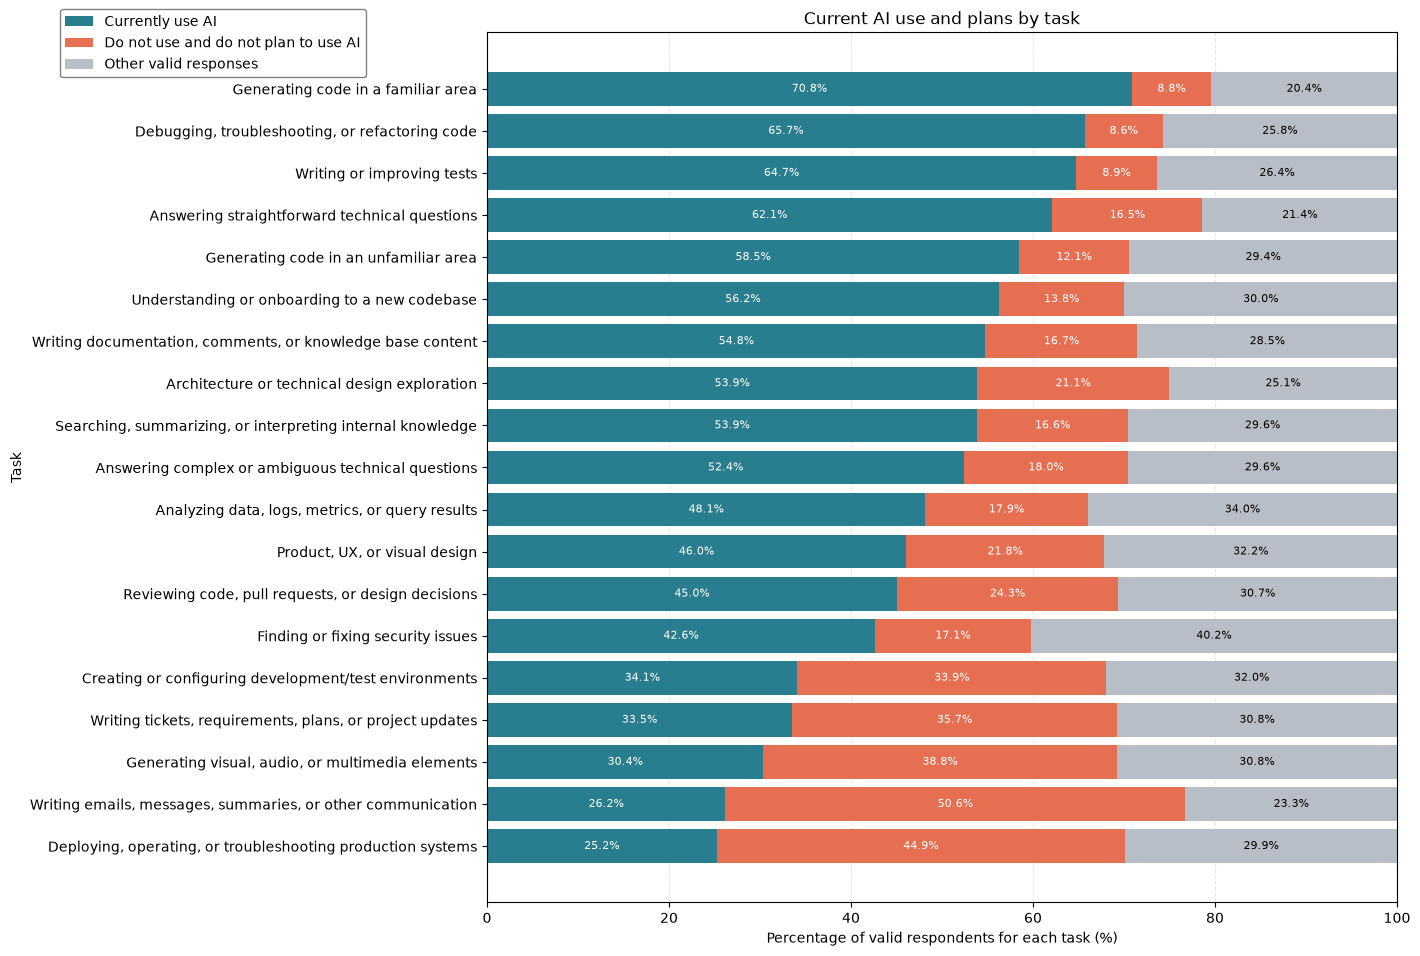

In [28]:
import matplotlib.pyplot as plt
import numpy as np

current_col = 'Currently use AI (%)'
no_plan_col = 'Do not use and do not plan to use AI (%)'
other_col = 'Other valid responses (%)'

current_use_comparison[other_col] = (100 - current_use_comparison[current_col] - current_use_comparison[no_plan_col]).clip(lower=0)
plot_data = current_use_comparison.sort_values(current_col).copy()
y = np.arange(len(plot_data))
current_pct = plot_data[current_col].to_numpy()
no_plan_pct = plot_data[no_plan_col].to_numpy()
other_pct = plot_data[other_col].to_numpy()

fig, ax = plt.subplots(figsize=(14, 10))

ax.barh(y, current_pct, color='#287d8e', label='Currently use AI')
ax.barh(y, no_plan_pct, left=current_pct, color='#e76f51', label='Do not use and do not plan to use AI')
ax.barh(y, other_pct, left=current_pct + no_plan_pct, color='#b8bec7', label='Other valid responses')

for i, (current, no_plan, other) in enumerate(zip(current_pct, no_plan_pct, other_pct)):
    if current >= 5: ax.text(current / 2, i, f'{current:.1f}%', ha='center', va='center', color='white', fontsize=8)
    if no_plan >= 5: ax.text(current + no_plan / 2, i, f'{no_plan:.1f}%', ha='center', va='center', color='white', fontsize=8)
    if other >= 5: ax.text(current + no_plan + other / 2, i, f'{other:.1f}%', ha='center', va='center', color='black', fontsize=8)

ax.set_yticks(y)
ax.set_yticklabels(plot_data.index)
ax.set_xlim(0, 100)
ax.set_xlabel('Percentage of valid respondents for each task (%)')
ax.set_ylabel('Task')
ax.set_title('Current AI use and plans by task')

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', bbox_to_anchor=(0.02, 0.98), frameon=True, facecolor='white', edgecolor='gray', framealpha=1)
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

fig.subplots_adjust(left=0.33, right=0.98, top=0.95, bottom=0.08)
plt.show()

# Conclusion (5 marks)

_Your concluding section should be around 200-400 words. It is recommended
that you divide it into the following sections._

### Achievements
_As we had expected, the most popular fridge magnets were of the 'meme' kind.
We were surprised that 'smiley' fridge magnets were less common than expected.
We conjecture that this is because, although they are apparently very popular,
few fridges display more than one smiley. However, 'meme' based magnets can
be found in large numbers, even on quite small fridges._

### Limitations

_The project was limited to a small number of fridge magents, which may not be
typical of fridges found in the global fridge magnet ecosystem._

### Future Work

_In future work we would like to obtain more diverse data and study fridge magnets 
beyond the limited confines of student accomodation. We hypothesise that there
could be a link between fridge magnet types and social class and/or educational
achievement._


<!-- 与组员共同替换以上示例：Achievements 汇总实际发现，并说明各成员从共同原表独立构建分析样本；Limitations 说明展示条件、原因未知的缺失、各自 N 及自报预期；Future Work 提出可行改进。仅在口径一致时直接比较，运行后保存展示输出。 -->